# 벤치마크 난이도 소폭 완화 비교

**기존 `data/evaluation`을 난이도 완화 데이터로 변경했습니다.** 별도의 활성 평가셋은 없습니다. 변경 전 데이터는 복구·비교 근거로 `reports/benchmark_before_mild_20261014`에 보관했습니다. 모델은 v12 그대로이고 STATUS=S, 기존 하드 룰 통과 조건, 정상 대조군과 사례 수를 유지했습니다.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'code/benchmark_difficulty').exists())
sys.path.insert(0, str(ROOT/'code'))
from benchmark_difficulty import report
from IPython.display import display
report.setup()

## 1. 조정 범위

- 개별/집단 지연, 컬럼 관계: 정상 값 대비 주입 편차를 1.2배로 강화.
- 폭주: 추가 실행 수를 1.2배, 정수 올림.
- 중단: 5/10/20분에서 6/12/24분.
- 점진적 악화: 증가량을 1.2배, 같은 진행 모양 유지.
- 모든 소요시간은 원래 고정 하드 룰 상한을 유지.
- **혼합 Hard는 변경하지 않음.**

20%는 신호 변화량이며 난이도 또는 F1의 변화율이 아닙니다. 원본 v12 평가와 동일하게 피처 float32 round-trip을 사용합니다. 직접 float64 평가 시 경계 근처에서 일부 판정이 달라지는 진단 결과는 별도로 보존했습니다.

In [2]:
protocol = json.loads((ROOT/'reports/benchmark_mild_v1/protocol.json').read_text(encoding='utf-8'))
display(protocol)

{'difficulty_profile': {'version': 'esb-process-synthetic-mild-v1',
  'excess_multiplier': 1.2,
  'stop_duration_multiplier': 1.2,
  'mixed_hard': 'unchanged',
  'normal_controls': 'byte-identical copies',
  'selection': 'all original cases, independent of model scores',
  'interpretation': 'benchmark sensitivity, not improved model performance'},
 'model_sha256': {'reports\\model_research_v12\\handoff\\if_v12_candidate.joblib': '8f5e743813758fe4fcb06107228380f82c4cf5fc01c044fb83733d23395f9bd0',
  'reports\\model_research_v12\\handoff\\kmeans_v12_candidate.joblib': '12b347486e910b6b9be2a2429004c8779d64ac57b33c63627ac8208547515a63'},
 'benchmark_manifest_sha256': '7f2dc4351af6166416f7694df97fb2050cab8d348e5b29d8451fcc36031f3b36',
 'model_refit': False,
 'threshold_refit': False,
 'case_selection_by_score': False,
 'point_adjustment': False,
 'mixed_hard_byte_identical': True,
 'full_validation_required_before_summary': True,
 'feature_precision': 'float32 round-trip matching original v1

## 2. 하드 룰과 원본 보존 검증

최종 CSV를 실제 파이프라인 규칙으로 재검사합니다. 원본 데이터와 모델은 해시로 보존 여부를 확인합니다.

In [3]:
validation = json.loads((ROOT/'data/evaluation/validation.json').read_text(encoding='utf-8'))
assert validation['passed']
display({'passed': validation['passed'], 'anomaly_cases': validation['anomaly_cases'], 'normal_cases': validation['normal_cases'], 'datasets': list(validation['datasets'])})
audit = json.loads((ROOT/'reports/benchmark_mild_v1/audit.json').read_text(encoding='utf-8'))
display(audit)
activation = json.loads((ROOT/'reports/benchmark_mild_v1/activation.json').read_text(encoding='utf-8'))
assert activation['state'] == 'active'
display({k:activation[k] for k in ('active_path','backup_path','verified','csv_files','model_files_unchanged')})

{'passed': True,
 'anomaly_cases': 31000,
 'normal_cases': 31000,
 'datasets': ['individual_delay',
  'group_delay',
  'column_relation',
  'time_burst',
  'input_stop',
  'gradual_degradation',
  'mixed_hard']}

{'passed': True,
 'anomaly_cases': 31000,
 'normal_cases': 31000,
 'decisions': 2167766,
 'rule_hits': 0,
 'unknown_rule_flags': 0,
 'all_status_S': True,
 'previous_version_backup_unchanged': True,
 'active_dataset_inplace_updated': True,
 'active_dataset_path': 'data/evaluation',
 'backup_path': 'reports/benchmark_before_mild_20261014',
 'frozen_models_unchanged': True,
 'normal_control_files_byte_identical': 12,
 'normal_shared_predictions_identical': 993986,
 'hard_all_files_byte_identical': True,
 'metrics_independently_recounted': True,
 'trend_cap_limited_cases': 495,
 'profile_fixed_before_scoring': True,
 'case_selection_by_score': False,
 'interpretation': 'benchmark sensitivity only; no model or threshold improvement claim'}

{'active_path': 'data/evaluation',
 'backup_path': 'reports/benchmark_before_mild_20261014',
 'verified': True,
 'csv_files': 67,
 'model_files_unchanged': True}

## 3. 전체 성능

Accuracy는 정상 비중에 영향을 받습니다. Precision·Recall·F1·정상 오탐률을 함께 확인하세요. Adapter/앙상블은 전용 모델이 없는 집단에서 전체 모델로 fallback합니다.

In [4]:
table = report.overall()
display(table[['모델', '원본 accuracy (%)', '완화 accuracy (%)', '원본 precision (%)', '완화 precision (%)', '원본 recall (%)', '완화 recall (%)']])
display(table[['모델', '원본 f1 (%)', '완화 f1 (%)', 'f1 변화 (%p)', '원본 normal_false_positive_rate (%)', '완화 normal_false_positive_rate (%)']])

,모델,원본 accuracy (%),완화 accuracy (%),원본 precision (%),완화 precision (%),원본 recall (%),완화 recall (%)
0,IF 전체,85.35,85.54,74.30,77.50,18.00,22.13
1,IF Adapter,84.73,84.66,73.29,76.14,12.72,15.42
2,IF 앙상블,85.11,85.16,69.13,72.16,18.74,21.96
3,K-means 전체,85.09,85.13,62.59,64.62,25.41,29.43
4,K-means Adapter,84.06,84.03,54.66,57.29,23.47,27.12
5,K-means 앙상블,84.63,84.69,57.59,59.95,28.20,32.27


,모델,원본 f1 (%),완화 f1 (%),f1 변화 (%p),원본 normal_false_positive_rate (%),완화 normal_false_positive_rate (%)
0,IF 전체,28.98,34.43,5.46,1.24,1.33
1,IF Adapter,21.68,25.65,3.97,0.92,1.00
2,IF 앙상블,29.49,33.67,4.18,1.67,1.75
3,K-means 전체,36.15,40.44,4.29,3.02,3.34
4,K-means Adapter,32.84,36.81,3.97,3.88,4.19
5,K-means 앙상블,37.86,41.96,4.10,4.14,4.46


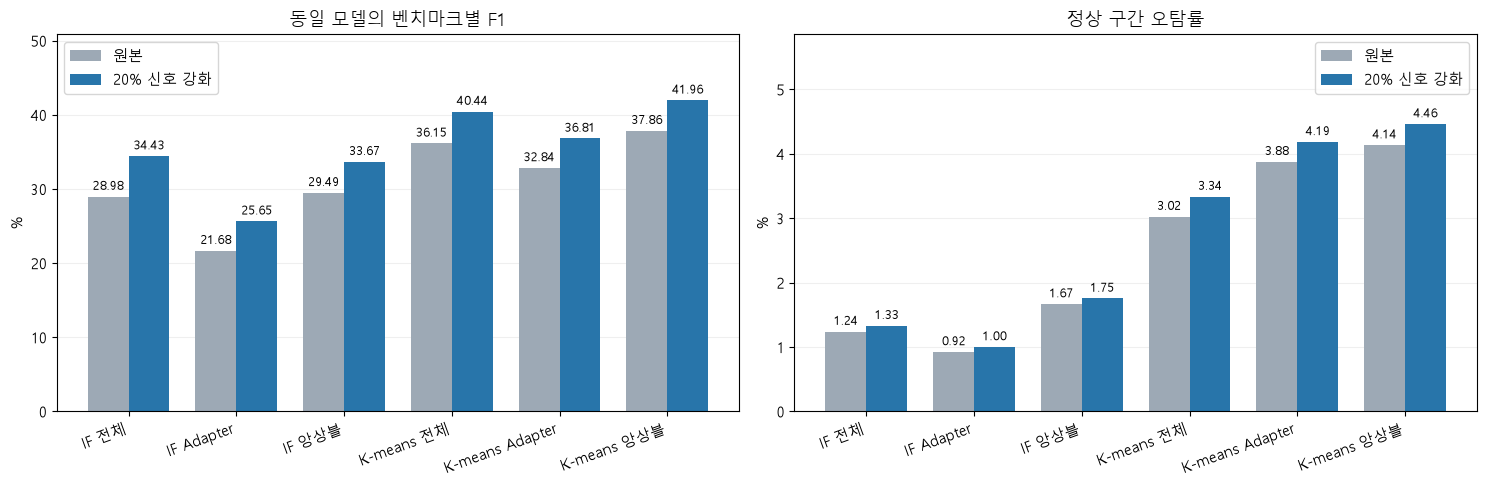

In [5]:
report.bars();

## 4. task별 성능

동일 모델이라도 task별 민감도가 다릅니다. 강도를 키워도 현재 피처와 threshold가 구분하지 못하면 성능이 그대로이거나 내려갈 수 있습니다. 모든 task를 유지하고 불리한 결과도 표시합니다.

,task,모델,원본 F1 (%),완화 F1 (%),F1 변화 (%p),원본 Recall (%),완화 Recall (%),원본 정상 오탐 (%),완화 정상 오탐 (%)
0,개별 지연,IF 전체,88.51,90.84,2.33,83.99,87.99,0.53,0.53
1,개별 지연,IF Adapter,56.32,65.26,8.94,39.27,48.52,0.02,0.02
2,개별 지연,IF 앙상블,60.56,66.81,6.25,43.70,50.47,0.06,0.06
3,개별 지연,K-means 전체,72.76,76.18,3.43,59.74,64.26,0.41,0.41
4,개별 지연,K-means Adapter,47.30,61.18,13.87,31.07,44.20,0.03,0.03
5,개별 지연,K-means 앙상블,72.58,76.00,3.42,59.52,64.02,0.41,0.41
6,집단 지연,IF 전체,17.43,19.71,2.27,10.69,12.37,2.13,2.35
7,집단 지연,IF Adapter,4.90,6.33,1.43,2.67,3.50,1.11,1.27
8,집단 지연,IF 앙상블,32.40,33.69,1.29,21.90,23.16,2.37,2.56
9,집단 지연,K-means 전체,58.94,60.52,1.58,65.82,69.64,10.25,10.80


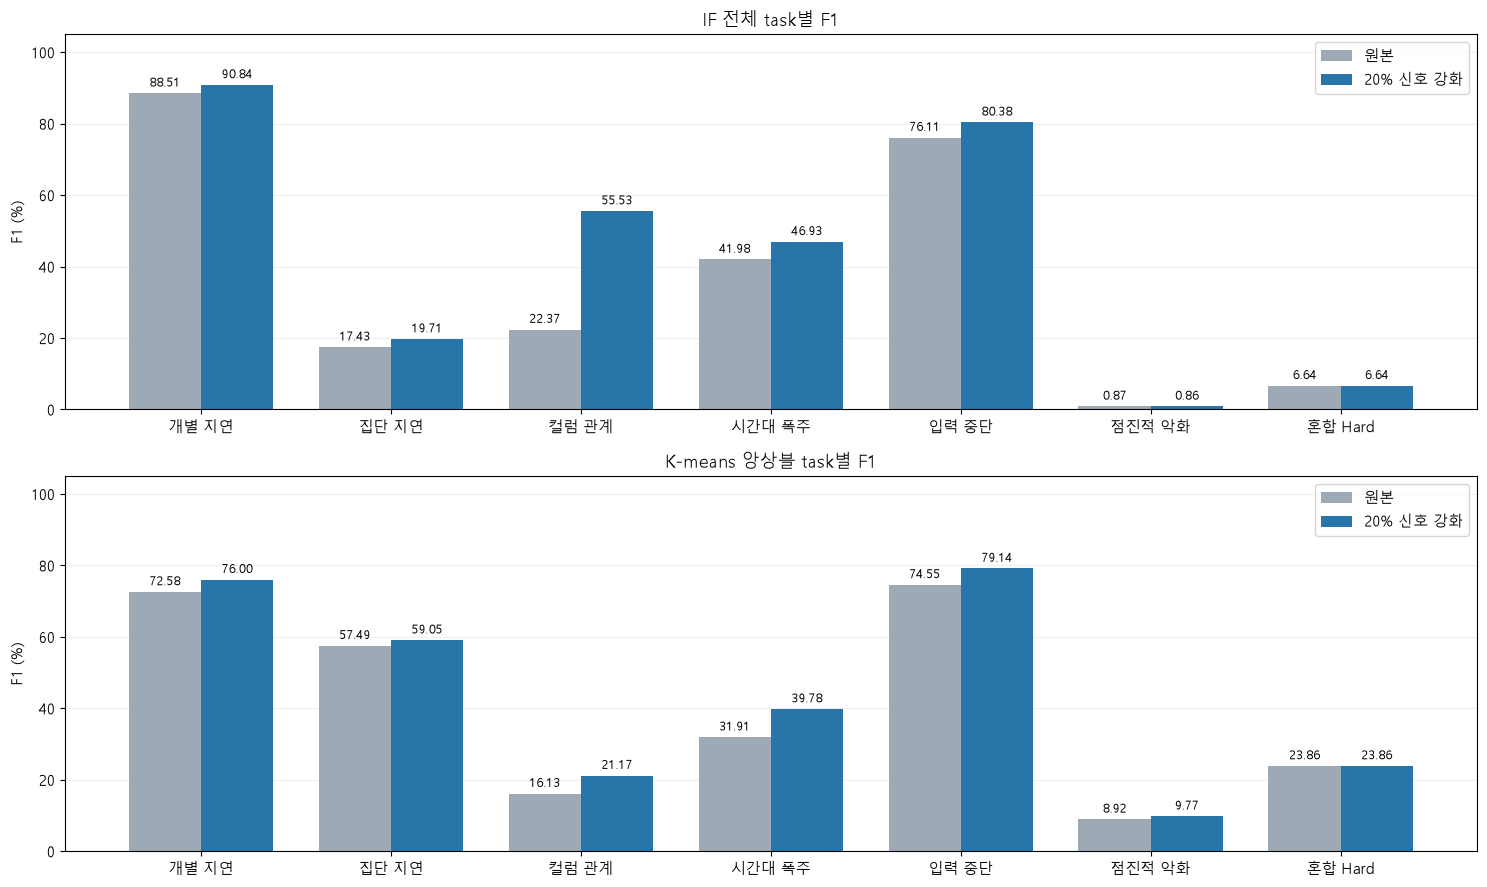

In [6]:
display(report.task_table())
report.task_bars();

## 5. 평가 분모 변화

사례 수는 그대로지만 중단 지속 시간이 늘어 이상 구간 수가 달라집니다. 소요시간 변화로 완료 시각이 넘어가면 판정 구간도 늘 수 있습니다. 전체 F1과 동일 task 비중의 macro 결과를 구분합니다.

In [7]:
display(report.denominators())
old = report.read('model_research_v12')
new = report.read('benchmark_mild_v1')
import pandas as pd
display(pd.DataFrame([{'모델': report.LABELS[i], '원본 task-macro F1 (%)': a['f1']*100, '완화 task-macro F1 (%)': b['f1']*100} for i,(a,b) in enumerate(zip(old['basic_macro'],new['basic_macro']))]).round(2))

,task,사례 수,원본 판정 구간,완화 판정 구간,원본 이상 구간,완화 이상 구간,정상 대조군 공통 구간 예측 동일
0,개별 지연,5000,59984,59984,5027,5070,True
1,집단 지연,5000,363830,363830,55047,55093,True
2,컬럼 관계,5000,60000,60000,10000,10000,True
3,시간대 폭주,5000,398856,398856,41663,41663,True
4,입력 중단,5000,502488,502488,58325,69990,True
5,점진적 악화,5000,602814,602814,149990,149990,True
6,혼합 Hard,1000,179794,179794,39997,39997,True


,모델,원본 task-macro F1 (%),완화 task-macro F1 (%)
0,IF 전체,41.21,49.04
1,IF Adapter,28.87,32.37
2,IF 앙상블,36.10,40.26
3,K-means 전체,42.36,46.50
4,K-means Adapter,36.42,41.26
5,K-means 앙상블,43.60,47.49


## 6. 사건 발견과 탐지 지연

사건 Recall은 장애 사건 중 한 번이라도 경보를 낸 비율입니다. 모든 이상 구간을 탐지했다는 뜻이 아니며, 이 값을 구간 F1로 대체하지 않습니다. 탐지 지연은 **탐지한 사건만**의 중앙값입니다.

In [8]:
rows=[]
for a,b in zip(old['datasets'],new['datasets']):
    previous={(r['scenario'],r['method']):r for r in a['events']['per_type']}
    for r in b['events']['per_type']:
        if r['method'] in ('if_global','kmeans_ensemble'):
            p=previous[(r['scenario'],r['method'])]
            rows.append({'데이터셋': report.TASKS[b['dataset']], '장애 유형': r['scenario'], '모델': r['method'], '원본 사건 Recall (%)':p['event_recall']*100,'완화 사건 Recall (%)':r['event_recall']*100,'원본 탐지 지연 (초)':p['median_delay_seconds'],'완화 탐지 지연 (초)':r['median_delay_seconds']})
display(pd.DataFrame(rows).round(2))

,데이터셋,장애 유형,모델,원본 사건 Recall (%),완화 사건 Recall (%),원본 탐지 지연 (초),완화 탐지 지연 (초)
0,개별 지연,individual_delay,if_global,84.44,89.22,60.0,60.0
1,개별 지연,individual_delay,kmeans_ensemble,59.84,64.92,60.0,60.0
2,집단 지연,group_delay,if_global,54.92,62.56,60.0,60.0
3,집단 지연,group_delay,kmeans_ensemble,90.28,92.80,120.0,120.0
4,컬럼 관계,column_relation,if_global,25.58,78.08,60.0,60.0
5,컬럼 관계,column_relation,kmeans_ensemble,17.54,23.68,60.0,60.0
6,시간대 폭주,time_burst,if_global,66.70,71.78,120.0,120.0
7,시간대 폭주,time_burst,kmeans_ensemble,51.36,63.04,180.0,120.0
8,입력 중단,input_stop,if_global,94.32,96.66,300.0,300.0
9,입력 중단,input_stop,kmeans_ensemble,82.86,95.48,300.0,300.0


## 결론을 읽는 기준

이 실험은 모델 성능 개선 주장이 아닙니다. **원본과 완화 벤치마크를 함께 보고** 신호 강도에 따른 민감도와 남은 실패 유형을 확인합니다. 같은 원본/생성기를 사용하며, 난이도 설정도 원본 결과를 본 뒤 정했으므로 외부 blind 평가가 아닙니다. 실제 운영 신뢰도는 별도 데이터가 필요합니다.